# C++ features, classifiers and grouped training

Executed research analysis on real local inputs or committed aggregate reports. Historical/validation scope is labeled explicitly. No test rescoring occurs. Use the isolated repository environment plus Jupyter, pandas and matplotlib.

In [1]:
from pathlib import Path
import os, json, hashlib, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'pyproject.toml').exists()
os.chdir(ROOT)
for path in [ROOT, ROOT / 'src']:
    if str(path) not in sys.path: sys.path.insert(0, str(path))
FIGURES = ROOT / 'docs' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))
def show_figure(fig, name):
    path = FIGURES / (name + '.png')
    fig.tight_layout()
    fig.savefig(path, dpi=140, bbox_inches='tight')
    plt.close(fig)
    display(Image(filename=str(path)))
print('Executed analysis; Python', sys.version.split()[0])
print('Only aggregate outputs and figures are retained; raw rows/weights remain ignored.')


Executed analysis; Python 3.14.2
Only aggregate outputs and figures are retained; raw rows/weights remain ignored.


## Algorithms directly in the notebook
Lexical normalization and structural covariates below are actual production definitions. They do not compile source or prove complexity. Candidate construction uses balanced lexical classifiers and structural forests. Calibration folds enforce group separation.

### Visible production core: `src/features/build_features.py`

These readable definitions are copied from the executed production module (SHA256 `d86ed2bd97e86cbc0b43e434a2999fa9248794f9012898f574ed002e371021f3`). They expose the algorithm directly; optional full studies still use production entrypoints and fresh outputs. No hidden source execution or encoded bootstrap is used.

In [2]:
"""Conservative lexical C++ normalization; never compiles untrusted source."""
import re
TOKEN = re.compile(r'R"[^\s()\\]{0,16}\(.*?\)[^\s()\\]{0,16}"|"(?:\\.|[^"\\])*"|\'(?:\\.|[^\'\\])*\'|//[^\n]*|/\*.*?\*/|[A-Za-z_]\w*|\d+(?:\.\d+)?|<<|>>|<=|>=|==|!=|\+\+|--|&&|\|\||[^\s]', re.S)
KEYWORDS = set('for while do if else return int long float double void auto const bool vector map set queue stack sort begin end size push_back lower_bound upper_bound break continue switch case struct class public private include using namespace std new delete true false sizeof'.split())
def tokenize(code):
    result=[]
    for token in TOKEN.findall(code):
        if token.startswith(('//','/*')): continue
        if token.startswith(('"',"'",'R"')): token='STR'
        elif token[0].isdigit(): token='NUM'
        elif re.fullmatch(r'[A-Za-z_]\w*',token) and token not in KEYWORDS: token='ID'
        result.append(token)
    return result

def normalized(code): return ' '.join(tokenize(code))


### Visible production core: `src/features/code_v2.py`

These readable definitions are copied from the executed production module (SHA256 `0618761393e3e0a71a1bc6df9ee8bd7b7555aabf5054bd9694d08d4070639b2a`). They expose the algorithm directly; optional full studies still use production entrypoints and fresh outputs. No hidden source execution or encoded bootstrap is used.

In [3]:
"""Name-invariant C++ lexical relationships and conservative structural features.

These are learned classifier covariates, not a formal C++ parser or Big-O proof.
"""
from collections import Counter
import math
import re
from sklearn.base import BaseEstimator, TransformerMixin
from src.features.build_features import TOKEN, KEYWORDS, normalized

LIBRARY = set(('unordered_map unordered_set priority_queue deque list multiset '
               'multimap pair tuple string swap max min abs sqrt log pow reverse '
               'accumulate count find binary_search nth_element next_permutation '
               'push pop top front back insert erase reserve resize clear empty '
               'emplace emplace_back int64_t uint64_t signed unsigned char short '
               'static inline template typename constexpr nullptr double float '
               'try catch throw virtual override operator typedef enum union').split())
RESERVED = KEYWORDS | LIBRARY
IDENTIFIER = re.compile(r'[A-Za-z_]\w*\Z')


def lex(code):
    if not isinstance(code, str):
        raise ValueError('C++ source must be text')
    tokens = []
    for token in TOKEN.findall(code):
        if token.startswith(('//', '/*')):
            continue
        tokens.append('STR' if token.startswith(('"', "'", 'R"')) else token)
    return tokens


def canonical(code):
    names, output = {}, []
    for token in lex(code):
        if token == 'STR':
            output.append(token)
        elif token[0].isdigit():
            output.append(token if token in {'0', '1', '2', '3'} else 'NUM')
        elif IDENTIFIER.fullmatch(token) and token not in RESERVED:
            if token not in names:
                names[token] = 'ID' + str(len(names))
            output.append(names[token])
        else:
            output.append(token)
    return ' '.join(output)


class CodeText(BaseEstimator, TransformerMixin):
    def __init__(self, representation='canonical'):
        self.representation = representation

    def fit(self, x, y=None):
        return self

    def transform(self, x):
        if self.representation not in {'canonical', 'legacy'}:
            raise ValueError('Unknown code representation')
        function = canonical if self.representation == 'canonical' else normalized
        return [function(code) for code in x]


def structural(code):
    tokens = lex(code)
    counts = Counter(tokens)
    pairs, stack = {}, []
    closing = {')': '(', ']': '[', '}': '{'}
    for i, token in enumerate(tokens):
        if token in {'(', '[', '{'}:
            stack.append((token, i))
        elif token in closing and stack and stack[-1][0] == closing[token]:
            _, start = stack.pop()
            pairs[start] = i

    def statement_end(i, depth=0):
        if i >= len(tokens) or depth > 100:
            return min(i, len(tokens)-1)
        if tokens[i] == '{':
            return pairs.get(i, i)
        if tokens[i] in {'for', 'while', 'if', 'switch'} and i+1 < len(tokens) and tokens[i+1] == '(':
            return statement_end(pairs.get(i+1, i+1)+1, depth+1)
        for j in range(i, len(tokens)):
            if tokens[j] == ';':
                return j
            if tokens[j] == '{':
                return pairs.get(j, j)
        return len(tokens)-1

    loops = []
    for i, token in enumerate(tokens[:-1]):
        if token in {'for', 'while'} and tokens[i+1] == '(' and i+1 in pairs:
            end_condition = pairs[i+1]
            loops.append((i, statement_end(end_condition+1)))
    maximum_nesting = max((sum(start <= i <= end for start, end in loops) for i, _ in loops), default=0)
    recursive_functions, maximum_self_calls, functions = 0, 0, 0
    controls = {'if', 'for', 'while', 'switch', 'catch'}
    for i in range(len(tokens)-2):
        if not IDENTIFIER.fullmatch(tokens[i]) or tokens[i] in controls or tokens[i+1] != '(':
            continue
        end = pairs.get(i+1)
        if end is None or end+1 >= len(tokens) or tokens[end+1] != '{':
            continue
        body_end = pairs.get(end+1, end+1)
        self_calls = sum(tokens[j] == tokens[i] and j+1 < body_end and tokens[j+1] == '('
                         for j in range(end+2, body_end))
        functions += 1
        recursive_functions += int(self_calls > 0)
        maximum_self_calls = max(maximum_self_calls, self_calls)
    depth, brace_depth = 0, 0
    for token in tokens:
        depth += int(token == '{') - int(token == '}')
        brace_depth = max(brace_depth, depth)
    result = {'log_tokens': math.log1p(len(tokens)), 'max_loop_nesting': maximum_nesting,
              'loops': len(loops), 'brace_depth': brace_depth, 'functions': functions,
              'recursive_functions': recursive_functions, 'maximum_self_calls': maximum_self_calls,
              'small_constant_2': math.log1p(counts['2']), 'small_constant_3': math.log1p(counts['3'])}
    for token in sorted(KEYWORDS | LIBRARY | {'[', '*', '/', '%', '<<', '>>', '++', '--'}):
        result['token:' + token] = math.log1p(counts[token])
    return result


class CodeStructure(BaseEstimator, TransformerMixin):
    def fit(self, x, y=None):
        return self

    def transform(self, x):
        return [structural(code) for code in x]


In [4]:
import argparse
import hashlib
import importlib.metadata
import json
from pathlib import Path
import platform
import time
import joblib
import numpy as np
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.feature_extraction import DictVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, log_loss
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import MaxAbsScaler
from sklearn.svm import LinearSVC
from threadpoolctl import threadpool_limits
from src.data.make_dataset import load
from src.features.code_v2 import CodeText, CodeStructure
from src.models.ensemble_v2 import EqualEnsemble, DenseArray

### Visible production core: `src/models/structure_v2.py`

These readable definitions are copied from the executed production module (SHA256 `5d88bdba400de6b75740e85ead548fdf1da31a120e3938c9869607360a1ddd9d`). They expose the algorithm directly; optional full studies still use production entrypoints and fresh outputs. No hidden source execution or encoded bootstrap is used.

In [5]:
def word(representation='canonical'):
    return Pipeline([('code', CodeText(representation)), ('tfidf', TfidfVectorizer(
        tokenizer=str.split, token_pattern=None, lowercase=False, ngram_range=(1, 3),
        min_df=2, sublinear_tf=True, max_features=75000))])


def structure():
    return Pipeline([('code', CodeStructure()), ('vectorize', DictVectorizer()), ('scale', MaxAbsScaler())])


def extra(leaf):
    return ExtraTreesClassifier(n_estimators=400, min_samples_leaf=leaf, max_features=.8,
                                class_weight='balanced', random_state=42, n_jobs=2)


def grouped_cv(x, y, groups):
    folds = list(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42).split(x, y, groups))
    expected = set(y)
    for train, val in folds:
        if set(y[train]) != expected or set(y[val]) != expected:
            raise ValueError('Insufficient independent class groups for calibration')
        if set(groups[train]) & set(groups[val]):
            raise ValueError('Calibration groups overlap')
    return folds


def candidates(x, y, groups, followup=False):
    if followup:
        base = Pipeline([('features', structure()), ('classifier', extra(1))])
        smooth = Pipeline([('features', structure()), ('classifier', extra(3))])
        models = [('structure_extra_leaf1', base)]
        for leaf in [2, 5]:
            models.append((f'structure_extra_leaf{leaf}', Pipeline([('features', structure()), ('classifier', extra(leaf))])))
        unweighted = clone(base).set_params(classifier__class_weight=None)
        models.append(('structure_extra_unweighted', unweighted))
        models.append(('structure_calibrated_sigmoid', CalibratedClassifierCV(base, cv=grouped_cv(x,y,groups), method='sigmoid', n_jobs=1)))
        legacy = Pipeline([('features', word('legacy')), ('classifier', LogisticRegression(C=16,class_weight='balanced',max_iter=3000,random_state=42))])
        models.append(('legacy_structure_equal', EqualEnsemble([legacy, smooth])))
        if followup == 'weights':
            return [models[-1]] + [(f'legacy_structure_weight{int(w*100)}', EqualEnsemble([legacy, smooth], weights=[w,1-w])) for w in [.25,.75]]
        return models
    logistic = lambda c: LogisticRegression(C=c, class_weight='balanced', max_iter=3000, random_state=42)
    canonical = Pipeline([('features', word()), ('classifier', logistic(16))])
    calibrated = CalibratedClassifierCV(Pipeline([('features', word()), ('classifier',
        LinearSVC(C=1., class_weight='balanced', random_state=42, max_iter=5000))]),
        cv=grouped_cv(x, y, groups), method='sigmoid', n_jobs=1)
    structural = Pipeline([('features', structure()), ('classifier', extra(3))])
    char = Pipeline([('code', CodeText()), ('tfidf', TfidfVectorizer(
        analyzer='char', ngram_range=(3, 5), min_df=2, sublinear_tf=True, max_features=75000))])
    latent = lambda n: Pipeline([('text', word()), ('svd', TruncatedSVD(n_components=n, random_state=42))])
    return [
        ('legacy_balanced_C16', Pipeline([('features', word('legacy')), ('classifier', logistic(16))])),
        ('legacy_unweighted_C4', Pipeline([('features', word('legacy')), ('classifier', LogisticRegression(C=4, max_iter=3000, random_state=42))])),
        ('canonical_balanced_C4', Pipeline([('features', word()), ('classifier', logistic(4))])),
        ('canonical_balanced_C16', canonical),
        ('canonical_wordchar_C16', Pipeline([('features', FeatureUnion([('word', word()), ('char', char)])), ('classifier', logistic(16))])),
        ('canonical_calibrated_SVC', calibrated),
        ('structure_extra_leaf1', Pipeline([('features', structure()), ('classifier', extra(1))])),
        ('structure_extra_leaf3', structural),
        ('latent128_structure_extra', Pipeline([('features', FeatureUnion([('latent', latent(128)), ('structure', structure())])), ('classifier', extra(2))])),
        ('latent64_structure_hist', Pipeline([('features', FeatureUnion([('latent', latent(64)), ('structure', structure())])), ('dense', DenseArray()),
            ('classifier', HistGradientBoostingClassifier(max_iter=150, max_leaf_nodes=15, l2_regularization=10, class_weight='balanced', random_state=42))])),
        ('fixed_equal_ensemble', EqualEnsemble([canonical, calibrated, structural]))]


def scores(model, x, y, labels):
    p = model.predict_proba(x)
    p = p[:, [list(model.classes_).index(label) for label in labels]]
    pred = np.asarray(labels)[p.argmax(axis=1)]
    gold = np.eye(len(labels))[[labels.index(label) for label in y]]
    return {'accuracy': float(accuracy_score(y, pred)),
            'macro_f1': float(f1_score(y, pred, labels=labels, average='macro', zero_division=0)),
            'log_loss': float(log_loss(y, p, labels=labels)),
            'multiclass_brier': float(np.mean(np.sum((p-gold)**2, axis=1)))}


## Executed compatible development comparisons
The family study preserves the same grouped folds and checks both OOF and validation. Higher validation alone did not qualify. This table reads actual tracked aggregates; no training or test rerun occurs.

,candidate,grouped_oof_macro_f1,validation_macro_f1,seconds
0,v2_baseline,0.558688,0.588250,111.947791
1,family_v2,0.553432,0.566020,38.200608
2,family_class_v2,0.563477,0.581089,78.934420
3,family_mechanics_leaf3,0.558972,0.680008,94.369333


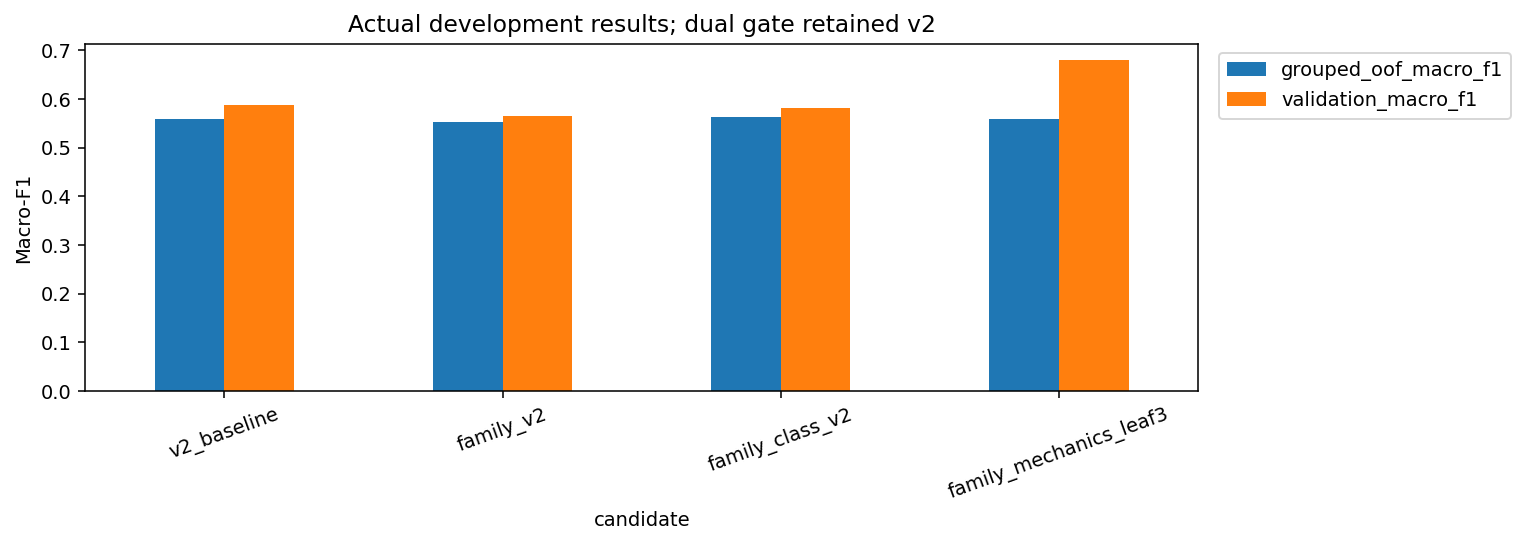

In [6]:
report = read_json('models/family-weight-v4/results.json')
comparison = pd.DataFrame([{'candidate':row['candidate'],'grouped_oof_macro_f1':row['oof']['macro_f1'],'validation_macro_f1':row['validation']['macro_f1'],'seconds':row['runtime_seconds']} for row in report['runs']])
display(comparison)
fig, ax = plt.subplots(figsize=(11,4))
comparison.set_index('candidate')[['grouped_oof_macro_f1','validation_macro_f1']].plot.bar(ax=ax)
ax.set(ylabel='Macro-F1',title='Actual development results; dual gate retained v2')
ax.tick_params(axis='x',rotation=20)
ax.legend(loc='upper left',bbox_to_anchor=(1.01,1))
show_figure(fig,'complexity_grouped_development')

## Optional full training
Training is deliberately disabled during this analysis execution. Enable only with cached real dataset/frozen split paths documented in Report.md. Production launcher preserves earlier reports and does not score the observed holdout.

In [7]:
RUN_TRAIN = False
if RUN_TRAIN:
    import subprocess
    from datetime import datetime, timezone
    output = 'models/notebook-family-' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
    subprocess.run([sys.executable,'train.py','family','--output',output],check=True)
print('Full study not executed by this notebook:', not RUN_TRAIN)

Full study not executed by this notebook: True


## Actual grouped fitting and selection loop
The following is the production family-study loop, shown directly rather than hidden in a wrapper. It fits each candidate on grouped folds, creates OOF predictions, evaluates development validation and applies the fixed dual gate. Defining it does not execute training. `__file__` identifies the copied source module for its provenance field. Use the root launcher for a new study; it creates a fresh output/plan. Source SHA256: `d948d54238c5c0a9fcb487bb1b9f869e9b843c9e0cae27689eb41df088c0327f`.

In [8]:
__file__ = str(ROOT / 'src/models/family_study.py')
import argparse
import json
import time
from pathlib import Path
import joblib
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import f1_score,accuracy_score,classification_report
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MaxAbsScaler
from threadpoolctl import threadpool_limits
from src.features.mechanics_v3 import CodeMechanics
from src.models.structure_v2 import word,structure,extra,grouped_cv,scores,sha
from src.models.ensemble_v2 import EqualEnsemble
from sklearn.linear_model import LogisticRegression
from src.data.make_dataset import load

def candidate(name):
    from src.models.mechanics_v3 import candidate as base
    from src.models.family_v4 import FamilyEnsemble
    if name=='v2_baseline':return base(name)
    if name not in ['family_v2','family_class_v2','family_mechanics_leaf3']:raise ValueError('Unknown family candidate')
    return FamilyEnsemble(mode='family_class' if name=='family_class_v2' else 'family',mechanics=name=='family_mechanics_leaf3')


def trained(name,x,y,groups):
    model=candidate(name)
    return model.fit(x,y) if name=='v2_baseline' else model.fit(x,y,groups)


def gate(runs,minimum=.005):
    baseline=next(r for r in runs if r['candidate']=='v2_baseline')
    eligible=[r for r in runs if r['oof']['macro_f1']>=baseline['oof']['macro_f1']+minimum and r['validation']['macro_f1']>=baseline['validation']['macro_f1']+minimum]
    return max(eligible,key=lambda r:r['oof']['macro_f1'])['candidate'] if eligible else 'v2_baseline'


def run(output='models/family-weight-v4'):
    output=Path(output)
    if (output/'selection.json').exists():raise ValueError('Preserve completed grouped study')
    plan=json.loads((output/'plan.json').read_text(encoding='utf-8'))
    data=Path('data/processed/tasty-time_complexity.jsonl');split_path=Path('models/tasty-optimized/split.json')
    if sha(data)!=plan['dataset_sha256'] or sha(split_path)!=plan['split_sha256']:raise ValueError('Frozen corpus/split changed')
    split=json.loads(split_path.read_text());rows=load(data)
    x=np.asarray([r['code'] for r in rows]);y=np.asarray([r['label'] for r in rows]);groups=np.asarray(split['groups']);labels=split['label_order']
    tr=np.asarray(split['partitions']['train']);va=np.asarray(split['partitions']['validation'])
    folds=grouped_cv(x[tr],y[tr],groups[tr]);local=Path('data/interim')/output.name;local.mkdir(parents=True,exist_ok=True)
    runs=[];failures=[];started=time.monotonic()
    with threadpool_limits(limits=2):
        for name in plan['candidates']:
            if time.monotonic()-started>plan['maximum_cpu_wall_seconds']:
                failures.append({'candidate':name,'reason':'Declared budget exhausted before fit'});break
            begin=time.monotonic()
            try:
                prediction=np.empty(len(tr),dtype=object);fold_reports=[]
                for train,val in folds:
                    model=trained(name,x[tr[train]],y[tr[train]],groups[tr[train]])
                    prediction[val]=model.predict(x[tr[val]])
                    fold_reports.append({'rows':len(val),'macro_f1':float(f1_score(y[tr[val]],prediction[val],labels=labels,average='macro',zero_division=0)),
                                         'group_overlap':len(set(groups[tr[train]])&set(groups[tr[val]]))})
                model=trained(name,x[tr],y[tr],groups[tr])
                result={'candidate':name,'oof':{'macro_f1':float(f1_score(y[tr],prediction,labels=labels,average='macro',zero_division=0)),
                                              'accuracy':float(accuracy_score(y[tr],prediction)),
                                              'classification_report':classification_report(y[tr],prediction,labels=labels,output_dict=True,zero_division=0)},
                        'folds':fold_reports,'validation':scores(model,x[va],y[va],labels),'runtime_seconds':time.monotonic()-begin}
                runs.append(result)
                joblib.dump(model,output/(name+'-validation.joblib'))
                (local/(name+'-oof-predictions.json')).write_text(json.dumps([{'row':int(i),'true':str(y[i]),'prediction':str(p)} for i,p in zip(tr,prediction)]))
                print(json.dumps(result),flush=True)
            except Exception as error:
                failures.append({'candidate':name,'error':type(error).__name__,'reason':str(error)})
    if not any(r['candidate']=='v2_baseline' for r in runs):raise ValueError('Baseline failed; comparison not valid')
    selected=gate(runs)
    report={'plan_sha256':sha(output/'plan.json'),'implementation_sha256':sha(__file__),
            'weighting_sha256':sha('src/models/family_v4.py'),'runs':runs,'failures':failures,'selected':selected,
            'deployment_changed':selected!='v2_baseline','test_evaluated':False,'runtime_seconds':time.monotonic()-started,
            'disclosure':plan['disclosure']}
    (output/'selection.json').write_text(json.dumps(report,indent=2,allow_nan=False))
    if selected=='v2_baseline':
        report['retained_checkpoint_sha256']=sha('models/structure-v2-weights/model.joblib')
        (output/'results.json').write_text(json.dumps(report,indent=2,allow_nan=False))
    return report


## Recorded execution identity
These values describe the already executed retained run, not a new fit triggered by this notebook.

In [9]:
identity=read_json('models/structure-v2-weights/results.json')
print('Recorded runtime seconds:',identity['runtime_seconds'])
print('Recorded environment:',identity['environment'])
print('Recorded selected candidate:',read_json('models/structure-v2-weights/evaluation.json')['selected_candidate'])
print('Retained model checkpoint SHA256:',read_json('models/structure-v2-weights/evaluation.json')['checkpoint_sha256'])

Recorded runtime seconds: 33.04261249999399
Recorded environment: {'python': '3.14.2', 'numpy': '2.4.2', 'scikit-learn': '1.8.0', 'rapidfuzz': '3.14.6'}
Recorded selected candidate: legacy_structure_weight25
Retained model checkpoint SHA256: e61c138907645ca751a8d130dd2471fc359abc6edb0827728086ce3f3bd0e6cf


In [10]:
example = Path('examples/linear.cpp').read_text(encoding='utf-8')
assert normalized(example)
features = CodeStructure().transform([example])
print('Public example structural covariates:', len(features[0]))
print('Candidate models and grouping logic are visible above; recorded metrics come from frozen runs.')

Public example structural covariates: 118
Candidate models and grouping logic are visible above; recorded metrics come from frozen runs.
